In [1]:
import os, json
import pandas as pd

In [2]:
# creating a dataframe of all of the annotator profiles
SCORED_ANNOTATOR_DIR = "annotation_artefacts/scored_passed_annotators"
os.makedirs(SCORED_ANNOTATOR_DIR, exist_ok=True)

df_list = []
for annfilename in os.listdir(SCORED_ANNOTATOR_DIR):
    annotator_filepath = os.path.join(SCORED_ANNOTATOR_DIR, annfilename)
    with open(annotator_filepath, "r") as  ao:
        annotator_object = json.load(ao)
    
    prompt_lengths = []
    prompt_type_freq_table = {
        "imperative" : 0,
        "interrogative" : 0,
        "declarative" : 0,
    }
    for v in annotator_object["answers"].values():
        if v["answer"]:
            prompt_lengths.append(v["sentence_length"])
            prompt_type_freq_table[v["sentence_type"]] += 1

    df_list.append({
        "id" : annotator_object["id"],
        **annotator_object["profile"],
        "sum_sentence_lengths" : sum(prompt_lengths),
        **prompt_type_freq_table
    })

df_list = sorted(df_list, key=lambda x: x["id"])

In [3]:
df = pd.DataFrame(df_list)
df.head()

,id,Participant id,Time taken,Total approvals,Gender,Highest education level completed,Employment-sector,English speaking monolingual,Age,Sex,...,Country of birth,Country of residence,Nationality,Language,Student status,Employment status,sum_sentence_lengths,imperative,interrogative,declarative
0,0,5b915c9d22d85d000115c0f5,1564.0,6210.0,Woman (including Trans Female/Trans Woman),Undergraduate degree (BA/BSc/other),Arts,I only know English,39.0,Female,...,United States,United States,United States,English,No,Part-Time,321,20,6,0
1,1,66a64ac60e8a5d708f667760,2091.0,134.0,Woman (including Trans Female/Trans Woman),Graduate degree (MA/MSc/MPhil/other),Hospitality & Tourism,I know one other language in addition to English,27.0,Female,...,Canada,Canada,Canada,English,No,Full-Time,331,22,2,0
2,2,66b222953abf68268269922f,3515.0,35.0,Woman (including Trans Female/Trans Woman),Undergraduate degree (BA/BSc/other),Education & Training,I know one other language in addition to English,26.0,Female,...,Canada,Canada,Canada,English,No,Full-Time,646,22,5,0
3,3,62b4548f1ec615632d50d4a7,3249.0,281.0,Woman (including Trans Female/Trans Woman),Undergraduate degree (BA/BSc/other),Manufacturing,I only know English,34.0,Female,...,United Kingdom,United Kingdom,United Kingdom,English,No,Full-Time,397,7,20,0
4,4,650062cd6cef58594c7a5c78,3828.0,723.0,Woman (including Trans Female/Trans Woman),Undergraduate degree (BA/BSc/other),Education & Training,I only know English,41.0,Female,...,Canada,Canada,Canada,English,No,Full-Time,542,19,10,0


In [4]:
from src.classes.AnnotatorManager import AnnotatorManager
from src.utils.viz_utils import plot_histogram_by_category, plot_grouped_bar_chart
import matplotlib.pyplot as plt
import numpy as np

In [5]:
aggregates = {}
for agg_attributes in ["sum_sentence_lengths", "interrogative", "declarative", "imperative"]:
    if agg_attributes == "sum_sentence_lengths":
        method = "list"
    else:
        method = "sum"
    aggregates[agg_attributes] = AnnotatorManager.get_profile_of_question(df, filler=agg_attributes, method=method)

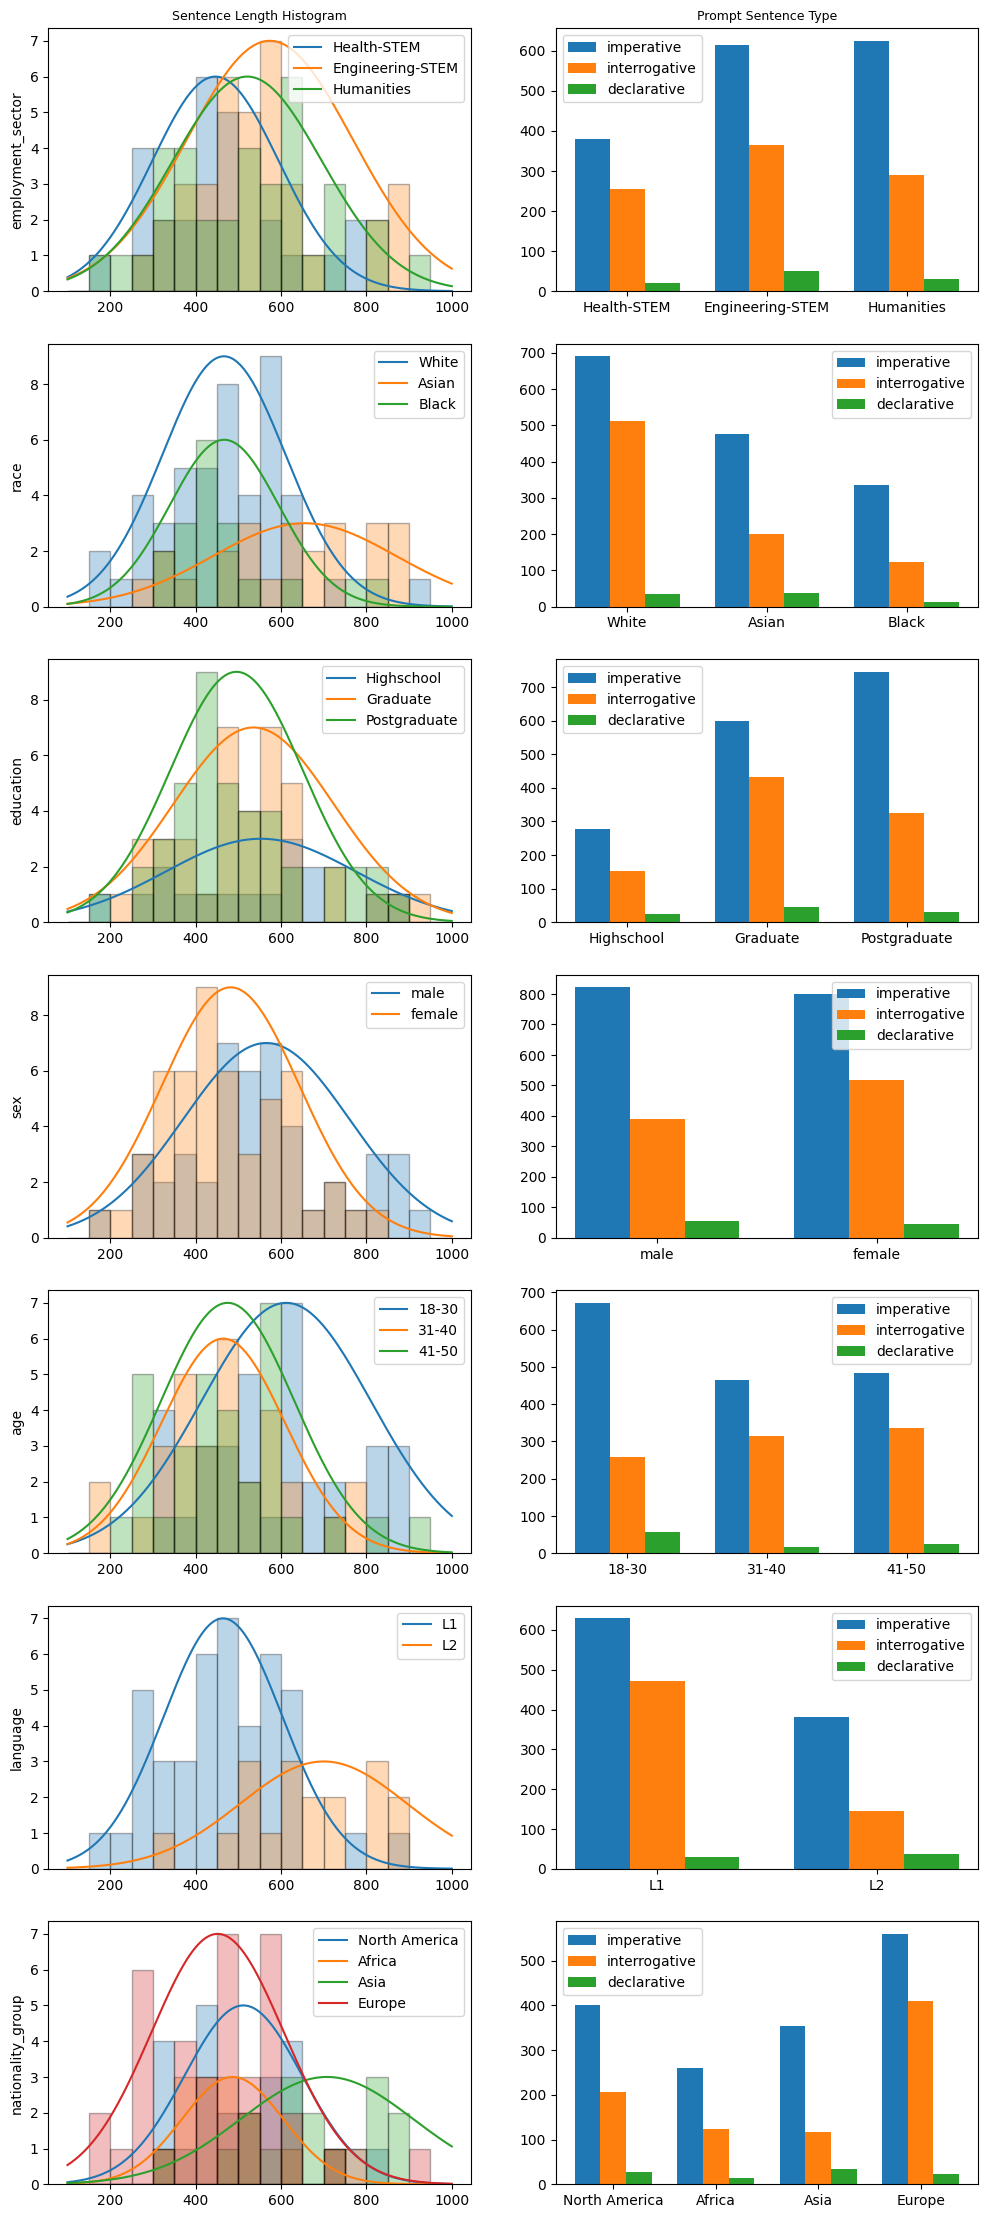

In [6]:
N = len(aggregates["sum_sentence_lengths"])
fig, axes = plt.subplots(N, 2, figsize=(12, 4 * N))

column_labels = ['Sentence Length Histogram', 'Prompt Sentence Type']
for col, label in enumerate(column_labels):
    axes[0, col].set_title(label, fontsize=9)

# Row labels
row_labels = [k for k in aggregates["sum_sentence_lengths"].keys()]
for row, label in enumerate(row_labels):
    axes[row, 0].set_ylabel(label, fontsize=10, rotation=90)


nrows, ncols = axes.shape
for i, j in np.ndindex(nrows, ncols):
    ax = axes[i, j]
    demo_graph = list(aggregates["sum_sentence_lengths"].keys())[i]
    if j == 0:
        data = aggregates['sum_sentence_lengths'][demo_graph]
        plot_histogram_by_category(data, ax)
    else:
        data = {}
        for d in aggregates["interrogative"][demo_graph].keys():
            data[d] = {}
            for senttype in ["imperative", "interrogative", "declarative"]:
                data[d][senttype] = aggregates[senttype][demo_graph][d]
        plot_grouped_bar_chart(data, ax)

In [7]:
from src.classes.Questions import Questions

questions = Questions().get_questions()
MODEL_TO_VIZ = "Qwen25_7B_Inst"

# creating a dataframe of all of the annotator profiles
SCORED_ANNOTATOR_DIR = "annotation_artefacts/scored_passed_annotators"

downstream_score_df_list = []
for annfilename in os.listdir(SCORED_ANNOTATOR_DIR):
    annotator_filepath = os.path.join(SCORED_ANNOTATOR_DIR, annfilename)
    with open(annotator_filepath, "r") as  ao:
        annotator_object = json.load(ao)
    
    downstream_scores = {}
    for question_key, values in annotator_object["answers"].items():
        if values["answer"] == None:
            continue
        for qid, score_s in values["downstream_scores"][MODEL_TO_VIZ].items():
            postfix = questions[question_key]["metrics"][0] # first metric entry is by convention default
            matching_keys = [k for k in score_s if k.endswith(f"{postfix}_score")]
            if not matching_keys:
                raise ValueError(f"No key ends with '{postfix}' for qid {qid}")
            correct_key = matching_keys[0]
            downstream_scores[f"{qid}-sentence_type"] = values["sentence_type"]
            downstream_scores[f"{qid}-sentence_length"] = values["sentence_length"]
            downstream_scores[correct_key] = score_s[correct_key]

    downstream_score_df_list.append({
        "id" : annotator_object["id"],
        **downstream_scores,
    })

score_df_list = sorted(downstream_score_df_list, key=lambda x: x["id"])
df = pd.DataFrame(score_df_list)
df.to_csv(f"lm_harness_processed/raw-{MODEL_TO_VIZ}.csv")

/Users/rayendito/miniconda3/envs/pietorch/lib/python3.12/site-packages/scipy/stats/_distn_infrastructure.py:2027: RuntimeWarning: divide by zero encountered in divide
  x = np.asarray((x - loc)/scale, dtype=dtyp)
/Users/rayendito/Documents/prompt-fairness/src/utils/viz_utils.py:35: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()




In [ ]:
cols = [col for col in df.columns if col != 'id']
number_of_tasks = len(cols)//3
fig, axes = plt.subplots(number_of_tasks, 1, figsize=(10, 4 * number_of_tasks))
assert len(axes) == len(range(0, len(cols), 3))

length_correlation_df = []
for i in range(0, len(cols), 3):
    chunk_cols = cols[i:i+3]
    subset_df = df[chunk_cols].dropna()
    task_name = "-".join(chunk_cols[-1].split("-")[:-2])
    
    
    prompt_type_freqtable = {}
    for _, row in subset_df.iterrows():
        ptype = row.to_dict()[chunk_cols[0]]
        score = row.to_dict()[chunk_cols[-1]]
        if ptype in prompt_type_freqtable:
            prompt_type_freqtable[ptype].append(score)
        else:
            prompt_type_freqtable[ptype] = [score]
    
    prompt_type_freqtable = dict(sorted(prompt_type_freqtable.items()))

    axes[i].set_ylabel(task_name, fontsize=10, rotation=90)
    bin_edges=np.arange(0,1,10)
    plot_histogram_by_category(prompt_type_freqtable, axes[i], bin_edges=bin_edges)
    break
    pearson_corr = np.corrcoef(subset_df[chunk_cols[1]],
                               subset_df[chunk_cols[2]])
    length_correlation_df.append({
        "task_name" : task_name,
        f"{MODEL_TO_VIZ}-length_correlation" : pearson_corr[0][-1]
    })

lcdf = pd.DataFrame(length_correlation_df)
lcdf.to_csv(f"lm_harness_processed/prompt_length_correlation-{MODEL_TO_VIZ}.csv")